In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer,KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score,roc_curve, make_scorer, auc

# Data

In [ ]:

url = "https://raw.githubusercontent.com/CIMCB/MetabComparisonBinaryML/master/notebooks/data/MTBLS90.xlsx"

data = pd.read_excel(url, sheet_name="Data")
peak = pd.read_excel(url, sheet_name="Peak")

np.random.seed(42)

/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


There are no nans in the table!

In [ ]:
x = data.iloc[:, 4:]
y = data.iloc[:, 2]

print("Raw data NaNs: in features -  "+ str(np.any(np.isnan(x)))+", in labels - " + str(np.any(np.isnan(y))))
print("Raw data inf. numbers: in features -  "+ str(np.any(np.isinf(x)))+", in labels - " + str(np.any(np.isinf(y))))

Raw data NaNs: in features -  False, in labels - False
Raw data inf. numbers: in features -  False, in labels - False


In [ ]:
rows, cols = x.shape
print(rows)
cells = (rows * cols)*0.1
print(cells)

968
18295.2


# Dirty Data



## Missing Values

In [ ]:
x_10_nan = x.copy() #new datasets from x(matrix) data
x_50_nan = x.copy()

rows, cols = x.shape

cells = rows * cols

idx_10 = np.random.choice(cells, size=round(cells * 0.1), replace=False) # 10 percent
idx_50 = np.random.choice(cells, size=round(cells * 0.5), replace=False) # 50 percent

x_10_nan.values[np.unravel_index(idx_10, (rows, cols))] = np.nan
x_50_nan.values[np.unravel_index(idx_50, (rows, cols))] = np.nan

print(x_50_nan.head())
print(x_10_nan.head())

         M1        M2         M3         M4         M5        M6        M7  \
0       NaN  14.49947        NaN  12.043818  11.436392  16.07217       NaN   
1  15.17667       NaN  12.363773        NaN        NaN       NaN       NaN   
2       NaN  14.41941        NaN  11.234959  11.199970  15.22600       NaN   
3  15.12638  14.75630  13.001426        NaN        NaN  14.78994  16.47827   
4  15.20272       NaN  12.392280        NaN        NaN  15.75598       NaN   

          M8        M9       M10  ...      M180      M181      M182      M183  \
0        NaN       NaN       NaN  ...       NaN       NaN  21.28179  21.09176   
1        NaN       NaN  15.30044  ...       NaN  20.51608       NaN       NaN   
2  11.892685       NaN  14.70853  ...  20.46320       NaN       NaN  20.81883   
3  12.071310  7.467041  14.14922  ...       NaN  20.93957       NaN  20.82021   
4  11.914073  7.971302       NaN  ...  20.80482  19.82493       NaN       NaN   

       M184       M185      M186      M187  

## Wrong Values

In [ ]:
x_10_wrong = x.copy()
x_50_wrong = x.copy()

rows, cols = x.shape
cells = rows * cols

idx_10 = np.random.choice(cells, size=round(cells * 0.1), replace=False) #randomly selecting cells for wrong values
idx_50 = np.random.choice(cells, size=round(cells * 0.5), replace=False)

row_10, col_10 = np.unravel_index(idx_10, (rows, cols)) # converts to rows n cols
row_50, col_50 = np.unravel_index(idx_50, (rows, cols))


for i in range(len(row_10)):
    r = row_10[i]
    c = col_10[i]
    val = x_10_wrong.values[r, c]
    noise = val * np.random.uniform(0.1, 0.9)
    x_10_wrong.values[r, c] = val + np.random.choice([-1, 1]) * noise


for i in range(len(row_50)):
    r = row_50[i]
    c = col_50[i]
    val = x_50_wrong.values[r, c]
    noise = val * np.random.uniform(0.1, 0.9)
    x_50_wrong.values[r, c] = val + np.random.choice([-1, 1]) * noise


print(x.head())
print(x_10_wrong.head())
print(x_50_wrong.head())

         M1        M2         M3         M4         M5        M6        M7  \
0  14.98474  14.49947  12.097435  12.043818  11.436392  16.07217  17.01090   
1  15.17667  14.50172  12.363773  12.240458  11.577436  14.93265  16.90847   
2  15.35934  14.41941  12.510494  11.234959  11.199970  15.22600  17.17192   
3  15.12638  14.75630  13.001426  12.640496  11.244146  14.78994  16.47827   
4  15.20272  14.48083  12.392280  10.779516  10.968423  15.75598  17.20552   

          M8        M9       M10  ...      M180      M181      M182      M183  \
0  12.163277  7.705057  13.38406  ...  20.70097  20.19814  21.28179  21.09176   
1  11.900871  7.548416  15.30044  ...  21.68605  20.51608  21.25777  20.53935   
2  11.892685  7.596758  14.70853  ...  20.46320  20.34297  21.34793  20.81883   
3  12.071310  7.467041  14.14922  ...  21.36879  20.93957  21.09719  20.82021   
4  11.914073  7.971302  14.66248  ...  20.80482  19.82493  20.84250  20.31349   

       M184       M185      M186      M187  

# Original Data Scaling (split)

In [ ]:
#split data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=(1/3), stratify=y ,random_state=42)

#scale data (imputation is not needed, no nans)
scaler = StandardScaler()

x_train_log = np.log(x_train)
x_train = scaler.fit_transform(x_train_log)

x_test_log = np.log(x_test)
x_test = scaler.transform(x_test_log)

print("Scaled data NaNs: in train -  "+ str(np.any(np.isnan(x_train)))+", in test - " + str(np.any(np.isnan(x_test))))
print("Scaled data inf. numbers: in train -  "+ str(np.any(np.isinf(x_train)))+", in test - " + str(np.any(np.isinf(x_test))))

Scaled data NaNs: in train -  False, in test - False
Scaled data inf. numbers: in train -  False, in test - False


# Data Imputation (missing values)
For Imputation:
- 1) train-test split
- 2) impute
- 3) log transform
- 4) Scaler

For Dropping:
- 1) drop
- 2) train-test split
- 3) log transform
- 4) Scaler


## 10%

In [ ]:
#split data
x_train_10nan, x_test_10nan, y_train_10nan, y_test_10nan = train_test_split(x_10_nan, y, test_size=(1/3), stratify=y ,random_state=42)


### Simple Imputer

In [ ]:
# Simple Imputer
simple_imputer_10 = SimpleImputer(strategy='mean')
x_train_simple_10 = simple_imputer_10.fit_transform(x_train_10nan)
x_test_simple_10 = simple_imputer_10.transform(x_test_10nan)

x_train_simple_log_10 = np.log(x_train_simple_10)
x_test_simple_log_10 = np.log(x_test_simple_10)

scaler = StandardScaler()
x_train_simple_10 = scaler.fit_transform(x_train_simple_log_10)
x_test_simple_10 = scaler.transform(x_test_simple_log_10)

### Knn Imputer

In [ ]:
knn_imputer_10 = KNNImputer(n_neighbors=5)
x_train_knn_10 = knn_imputer_10.fit_transform(x_train_10nan)
x_test_knn_10 = knn_imputer_10.transform(x_test_10nan)

# log+scale
x_train_knn_log_10 = np.log(x_train_knn_10)
x_test_knn_log_10 = np.log(x_test_knn_10)

scaler_knn = StandardScaler()
x_train_knn_10 = scaler_knn.fit_transform(x_train_knn_log_10)
x_test_knn_10 = scaler_knn.transform(x_test_knn_log_10)

### Dropping rows

In [ ]:
x_drop_10 = x_10_nan.dropna()

print(x_drop_10.shape)

(0, 189)


doesnt work on models as it has null values


## 50%

In [ ]:
x_train_50nan, x_test_50nan, y_train_50nan, y_test_50nan = train_test_split(x_50_nan, y, test_size=1/3, stratify=y, random_state=42)

### Simple Imputer

In [ ]:
#Simple Imputer
simple_imputer_50 = SimpleImputer(strategy='mean')
x_train_simple_50 = simple_imputer_50.fit_transform(x_train_50nan)
x_test_simple_50 = simple_imputer_50.transform(x_test_50nan)

#log
x_train_simple_log_50 = np.log(x_train_simple_50)
x_test_simple_log_50 = np.log(x_test_simple_50)

#scale
scaler_simple_50 = StandardScaler()
x_train_simple_50 = scaler_simple_50.fit_transform(x_train_simple_log_50)
x_test_simple_50 = scaler_simple_50.transform(x_test_simple_log_50)

### KNN Imputer

In [ ]:
#KNN
knn_imputer_50 = KNNImputer(n_neighbors=5)
x_train_knn_50 = knn_imputer_50.fit_transform(x_train_50nan)
x_test_knn_50 = knn_imputer_50.transform(x_test_50nan)

#log
x_train_knn_log_50 = np.log(x_train_knn_50)
x_test_knn_log_50 = np.log(x_test_knn_50)

#scale
scaler_knn_50 = StandardScaler()
x_train_knn_50 = scaler_knn_50.fit_transform(x_train_knn_log_50)
x_test_knn_50 = scaler_knn_50.transform(x_test_knn_log_50)

### Dropping rows

In [ ]:
x_drop_50 = x_50_nan.dropna()

print(x_drop_50.shape)


(0, 189)


again, data with null values, doesnt work on models

# Wrong Data Scaling


## 10%

In [ ]:
x_train_wrong_10, x_test_wrong_10, y_train_wrong_10, y_test_wrong_10 = train_test_split(x_10_wrong, y, test_size=1/3, stratify=y, random_state=42)

#log+scale
x_train_log_10 = np.log(x_train_wrong_10)
x_test_log_10 = np.log(x_test_wrong_10)

scaler = StandardScaler()
x_train_wrong_10 = scaler.fit_transform(x_train_log_10)
x_test_wrong_10 = scaler.transform(x_test_log_10)

## 50%

In [ ]:
x_train_wrong_50, x_test_wrong_50, y_train_wrong_50, y_test_wrong_50 = train_test_split(x_50_wrong, y, test_size=1/3, stratify=y, random_state=42)

#loig + scale
x_train_log_50 = np.log(x_train_wrong_50)
x_test_log_50 = np.log(x_test_wrong_50)

scaler = StandardScaler()
x_train_wrong_50 = scaler.fit_transform(x_train_log_50)
x_test_wrong_50 = scaler.transform(x_test_log_50)

# Data Summary

### Original Data
- Clean, no missing or corrupted values
- Train/Test: `x_train`, `x_test`, `y_train`, `y_test`

---

### Missing 10% (raw)
- Cannot run directly (contains `NaN`)

### Missing 10% (Simple Imputer)
- Imputed with mean
- Train/Test: `x_train_simple_10`, `x_test_simple_10`, `y_train_10nan`, `y_test_10nan`

### Missing 10% (KNN Imputer)
- Imputed with KNN
- Train/Test: `x_train_knn_10`, `x_test_knn_10`, `y_train_10nan`, `y_test_10nan`

### Missing 10% (Dropped Rows)
- Rows with `NaN` removed --> no data left

---

### Missing 50% (raw)
- Cannot run directly (contains `NaN`)

### Missing 50% (Simple Imputer)
- Imputed with mean
- Train/Test: `x_train_simple_50`, `x_test_simple_50`, `y_train_50nan`, `y_test_50nan`

### Missing 50% (KNN Imputer)
- Imputed with KNN
- Train/Test: `x_train_knn_50`, `x_test_knn_50`, `y_train_50nan`, `y_test_50nan`

### Missing 50% (Dropped Rows)
- Rows with `NaN` removed --> no data left

---

### Wrong 10% (Corrupted Values)
- 10% of cells randomly altered
- Train/Test: `x_train_wrong_10`, `x_test_wrong_10`, `y_train_wrong_10`, `y_test_wrong_10`

### Wrong 50% (Corrupted Values)
- 50% of cells randomly altered
- Train/Test: `x_train_wrong_50`, `x_test_wrong_50`, `y_train_wrong_50`, `y_test_wrong_50`

In [ ]:
all_x_train = [x_train, x_train_10nan, x_train_10nan,  x_train_50nan, x_train_50nan, x_train_wrong_10, x_train_wrong_50]
all_x_test = [x_test, x_test_10nan, x_test_10nan,  x_test_50nan, x_test_50nan,  x_test_wrong_10, x_test_wrong_50]
all_y_train = [y_train, y_train_10nan, y_train_10nan,  y_train_50nan, y_train_50nan,  y_train_wrong_10, y_train_wrong_50]
all_y_test = [y_test, y_test_10nan, y_test_10nan,  y_test_50nan, y_test_50nan,  y_test_wrong_10, y_test_wrong_50]
names=['Original', 'Simple Imputer 10%', 'KNN Imputer 10%', 'Simple Imputer 50%', 'KNN Imputer 50%', 'Wrong 10%', 'Wrong 50%']
# print("Data Summary")
# print(len(all_x_train))
# print(len(all_x_test))
# print(len(all_y_train))
# print(len(all_y_test))

# Random Forest

## Training

We take the same approach as in the paper (same values) but by using

In [ ]:

rf_models = []
rf_train_scores = []
rf_test_scores = []

for i in range(len(all_x_train)):

  # param_dist = {
  # 'n_estimators':   [100],
  # 'max_features':  ['sqrt'],
  # 'max_depth': list(range(1,11)),
  # 'min_samples_split': [2],
  # 'min_samples_leaf': [0.01,0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5],
  # 'criterion': ['gini'],
  # 'max_leaf_nodes': [None],
  # }


  # rf = RandomForestClassifier(random_state=42)

  # random_search_rf = RandomizedSearchCV( rf, param_distributions=param_dist,
  # n_iter=20,
  # cv=5,
  # verbose=0,
  # random_state=42,
  # n_jobs=-1,
  # scoring="roc_auc"
  # )

  # random_search_rf.fit(all_x_train[i], all_y_train[i])
  rf = RandomForestClassifier(max_depth=7, min_samples_leaf=0.01, random_state=42)
  rf.fit(all_x_train[i], all_y_train[i])

  #rf=random_search_rf.best_estimator_
  y_pred_rf = rf.predict_proba(all_x_train[i])[:, 1]
  auc_rf = roc_auc_score(all_y_train[i], y_pred_rf)
  print(f"\nRF Model {names[i]} AUC Score (train):", auc_rf)
  rf_train_scores.append(auc_rf)

  y_pred_rf = rf.predict_proba(all_x_test[i])[:, 1]
  auc_rf = roc_auc_score(all_y_test[i], y_pred_rf)
  print(f"RF Model {names[i]} Score (test):", auc_rf)
  rf_test_scores.append(auc_rf)

  rf_models.append(rf)



RF Model Original AUC Score (train): 0.988500663423264
RF Model Original Score (test): 0.8271988344452113

RF Model Simple Imputer 10% AUC Score (train): 0.9942791762013731
RF Model Simple Imputer 10% Score (test): 0.8118242466068553

RF Model KNN Imputer 10% AUC Score (train): 0.9942791762013731
RF Model KNN Imputer 10% Score (test): 0.8118242466068553

RF Model Simple Imputer 50% AUC Score (train): 0.9951156664038612
RF Model Simple Imputer 50% Score (test): 0.795376121463078

RF Model KNN Imputer 50% AUC Score (train): 0.9951156664038612
RF Model KNN Imputer 50% Score (test): 0.795376121463078

RF Model Wrong 10% AUC Score (train): 0.9957406303482491
RF Model Wrong 10% Score (test): 0.7940341998313012

RF Model Wrong 50% AUC Score (train): 1.0
RF Model Wrong 50% Score (test): 0.7370983820259183


## Important features

In [ ]:
meta_code = x.columns  #exract feat.

for i, rf in enumerate(rf_models):
    importances_raw = rf.feature_importances_

    importances = pd.DataFrame({
        'Name': meta_code,
        'Importance': importances_raw
    })

    importances = importances.sort_values(by='Importance', ascending=False)
    top3_codes = importances.head(5)
    top3 = top3_codes.merge(peak, how='left', on='Name')

    print(f"\nRF Model {names[i]} - Top 5 Important Features")
    print(top3[['Name', 'Label', 'Importance']])


RF Model Original - Top 5 Important Features
   Name                                              Label  Importance
0  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    0.058827
1  M142                          Phosphatidylcholine(28:2)    0.057728
2   M10                                           Creatine    0.036186
3    M2                                         Creatinine    0.033528
4    M7                                            Betaine    0.032483

RF Model Simple Imputer 10% - Top 5 Important Features
   Name                                              Label  Importance
0  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    0.051913
1  M142                          Phosphatidylcholine(28:2)    0.048878
2   M10                                           Creatine    0.035388
3    M2                                         Creatinine    0.029052
4   M15                                2-Ketohexanoic acid    0.028898

RF Model KNN Imputer 10% - Top 5 Important Fe

# SVM - linear

##Training

In [ ]:
svm_models = []
svm_train_scores = []
svm_test_scores = []

for i in range(len(all_x_train)):
    #hyperparameter
    C_range = [0.0001, 0.001, 0.01, 0.1, 1, 10]
    param_grid = {'C': C_range, 'kernel': ['linear']}

    #model
    svm_model = SVC(probability=True)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid_search_svml = GridSearchCV(svm_model, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1, verbose=0)
    grid_search_svml.fit(all_x_train[i], all_y_train[i])  # Using the current dataset from the loop

    best_svmLmodel = grid_search_svml.best_estimator_

    # Evaluation on training data
    y_pred_svml = best_svmLmodel.predict_proba(all_x_train[i])[:, 1]
    auc_svml = roc_auc_score(all_y_train[i], y_pred_svml)
    print(f"\nSVM linear Model {names[i]} AUC Score (train):", auc_svml)
    svm_train_scores.append(auc_svml)

    # Evaluation on testing data
    y_pred_svml = best_svmLmodel.predict_proba(all_x_test[i])[:, 1]
    auc_svml = roc_auc_score(all_y_test[i], y_pred_svml)
    print(f"SVM linear Model {names[i]} AUC Score (test):", auc_svml)
    svm_test_scores.append(auc_svml)

    svm_models.append(best_svmLmodel) #save best model


SVM linear Model Original AUC Score (train): 0.876901332615426
SVM linear Model Original AUC Score (test): 0.8280806686603788

SVM linear Model Simple Imputer 10% AUC Score (train): 0.8772763109820587
SVM linear Model Simple Imputer 10% AUC Score (test): 0.8174219768422667

SVM linear Model KNN Imputer 10% AUC Score (train): 0.8744687806472704
SVM linear Model KNN Imputer 10% AUC Score (test): 0.8199907982516678

SVM linear Model Simple Imputer 50% AUC Score (train): 0.8835451800857643
SVM linear Model Simple Imputer 50% AUC Score (test): 0.8015489609692509

SVM linear Model KNN Imputer 50% AUC Score (train): 0.8677047478030113
SVM linear Model KNN Imputer 50% AUC Score (test): 0.7975998773100222

SVM linear Model Wrong 10% AUC Score (train): 0.8161163779012748
SVM linear Model Wrong 10% AUC Score (test): 0.5688789203281956

SVM linear Model Wrong 50% AUC Score (train): 0.802924831259735
SVM linear Model Wrong 50% AUC Score (test): 0.5426347672724485


##Important Features for all data

In [ ]:
meta_code = x.columns

for i, svm_model in enumerate(svm_models):
    importances_raw = np.abs(svm_model.coef_[0])  #absolute values of coefficients

    importances = pd.DataFrame({
        'Name': meta_code,
        'Importance': importances_raw
    })

    importances = importances.sort_values(by='Importance', ascending=False)
    top3_codes = importances.head(5)  #top 5 features
    top3 = top3_codes.merge(peak, how='left', on='Name')

    print(f"\nSVM linear Model {names[i]} - Top 5 Important Features")
    print(top3[['Name', 'Label', 'Importance']])


SVM linear Model Original - Top 5 Important Features
   Name                                              Label  Importance
0   M10                                           Creatine    0.106082
1  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    0.092073
2  M142                          Phosphatidylcholine(28:2)    0.091253
3    M2                                         Creatinine    0.089553
4   M18                                          Uric acid    0.076165

SVM linear Model Simple Imputer 10% - Top 5 Important Features
   Name                                              Label  Importance
0   M10                                           Creatine    0.108903
1    M2                                         Creatinine    0.085501
2  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    0.083537
3  M142                          Phosphatidylcholine(28:2)    0.077422
4  M152                          Sphingomyelin(d18:2/18:1)    0.075321

SVM linear Model KNN Imputer 

# Joint comparison

In [ ]:
for i, rf in enumerate(rf_models):
    y_pred_rf = rf.predict(all_x_test[i])
    acc = accuracy_score(all_y_test[i], y_pred_rf)

    print(f"RF Model {names[i]}: Accuracy = {acc:.4f}")


RF Model Original: Accuracy = 0.7678
RF Model Simple Imputer 10%: Accuracy = 0.7430
RF Model KNN Imputer 10%: Accuracy = 0.7554
RF Model Simple Imputer 50%: Accuracy = 0.7245
RF Model KNN Imputer 50%: Accuracy = 0.7090
RF Model Wrong 10%: Accuracy = 0.7337
RF Model Wrong 50%: Accuracy = 0.6811


In [ ]:
for i, svm in enumerate(svm_models):
    y_pred_svm = svm.predict(all_x_test[i])
    acc = accuracy_score(all_y_test[i], y_pred_svm)

    print(f"SVM Model {names[i]}: Accuracy = {acc:.4f}")

SVM Model Original: Accuracy = 0.7926
SVM Model Simple Imputer 10%: Accuracy = 0.7802
SVM Model KNN Imputer 10%: Accuracy = 0.7833
SVM Model Simple Imputer 50%: Accuracy = 0.7399
SVM Model KNN Imputer 50%: Accuracy = 0.7492
SVM Model Wrong 10%: Accuracy = 0.5356
SVM Model Wrong 50%: Accuracy = 0.5325


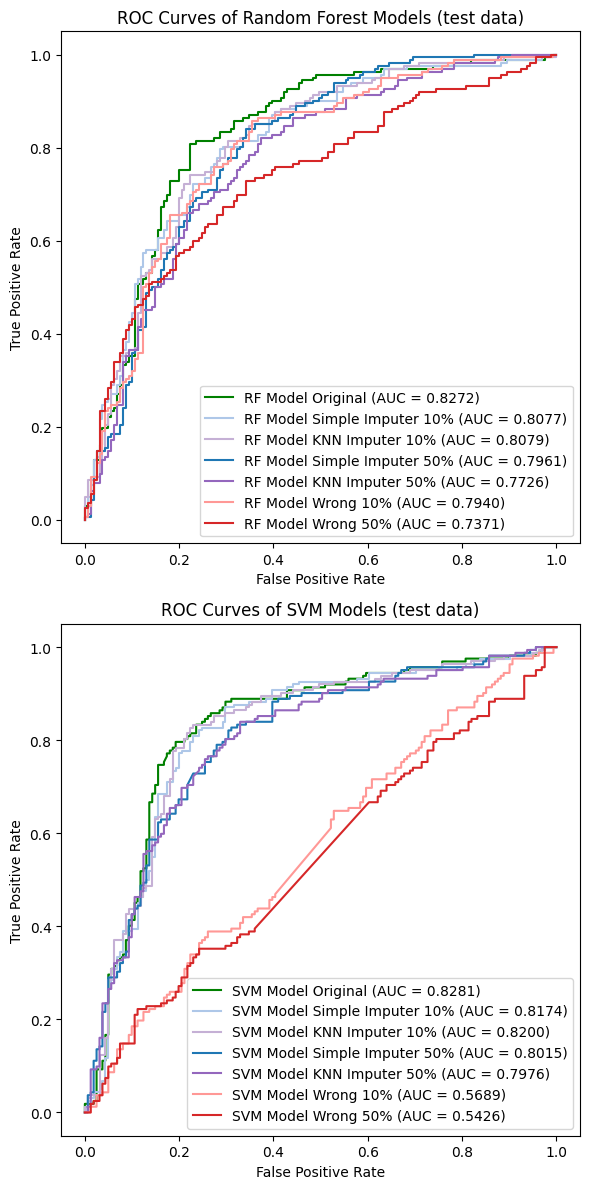

In [ ]:
colors = [
    #org
    'green',

    #imp10
    '#aec7e8',  # light blue
    '#c5b0d5',  # light purple

    #imp50
    '#1f77b4',  # dark blue
    '#9467bd',  # dark purple

    #wrong data 10-50
    '#ff9896',   # light red
    '#d62728'  # dark red

]

fig, axs = plt.subplots(2, 1, figsize=(6, 12))


for i, rf in enumerate(rf_models):
    y_pred_rf = rf.predict_proba(all_x_test[i])[:, 1]
    fpr, tpr, _ = roc_curve(all_y_test[i], y_pred_rf)
    auc_score = roc_auc_score(all_y_test[i], y_pred_rf)

    color = colors[i % len(colors)]
    axs[0].plot(fpr, tpr, label=f'RF Model {names[i]} (AUC = {auc_score:.4f})', color=color)

axs[0].set_title('ROC Curves of Random Forest Models (test data)')
axs[0].set_xlabel('False Positive Rate')
axs[0].set_ylabel('True Positive Rate')
axs[0].legend()


for i, svm in enumerate(svm_models):
    y_pred = svm.predict_proba(all_x_test[i])[:, 1]

    fpr, tpr, _ = roc_curve(all_y_test[i], y_pred)
    auc_score = roc_auc_score(all_y_test[i], y_pred)

    color = colors[i % len(colors)]
    axs[1].plot(fpr, tpr, label=f'SVM Model {names[i]} (AUC = {auc_score:.4f})', color=color)

axs[1].set_title('ROC Curves of SVM Models (test data)')
axs[1].set_xlabel('False Positive Rate')
axs[1].set_ylabel('True Positive Rate')
axs[1].legend()

plt.tight_layout()
plt.show()

# for i, rf in enumerate(rf_models):
#     y_pred_rf = rf.predict_proba(all_x_test[i])[:, 1]
#     fpr, tpr, t = roc_curve(all_y_test[i], y_pred_rf)
#     auc_score = roc_auc_score(all_y_test[i], y_pred_rf)

#     color = colors[i % len(colors)]
#     plt.plot(fpr, tpr, label=f'RF Model {names[i]} (AUC = {auc_score:.4f})', color=color)

# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('ROC Curves of Random Forest Models (test data)')
# plt.legend()
# plt.show()